# Graph construction
This notebook describes the bipartite graph construction.

In [3]:
from json import encoder

import networkx as nx
import pandas as pd
import numpy as np

In [4]:
JSON_STRUCTURE_PATH = "document_data_parsing/{doc_id}.json"

In [5]:
paragraph_dataset_mini = [
    "116062204", "116075685", "116080900", "116084352", "116084886", "116099338", "116102314", "116105977", "116106432", "116109598", "116110555", "116116081", "116118921", "116120654", "116121714", "116125191", "116126076", "116127831", "116141779", "116142769", "116149190", "116150283", "116167789", "116168634", "116170057", "116170822", "116192026", "116194637", "116196887", "116197578", "116199866", "116204676", "116213690", "116214232", "116220471", "116221948", "116226431", "116229939", "116232414", "116233794", "116245112", "116246991", "116248468", "116252607", "116253514", "116256069", "116257159", "116259036", "116260246", "116261015", "116261263", "116270112", "116277632", "116278949", "116283678", "116285648", "116289180", "116308208", "116310154", "116320626", "116321603", "116336690", "116339406", "116344031", "116350541", "116350825", "116358099", "116359089", "116376162", "116377931", "116385451", "116398308", "116410200", "116410462", "116414218", "116432495", "116434259", "116442566", "116462199", "116588653", "116681882", "116764649", "116780853", "116790074", "116794466", "116972204", "117069850", "117125134", "117130242", "117230819", "117251852", "117420480", "117440182", "117456818", "117460145", "117464049", "117489745", "117516936", "117556435"
]

In [6]:
from pathlib import Path
import json

In [7]:
def read_json_file(path: str):
    with open(path, "r") as doc_file:
        doc_file_contents = json.loads(doc_file.read())

    return doc_file_contents

In [8]:
def read_structures(doc_list: list[str]) -> dict:
    docs = {}
    for doc_id in doc_list:
        doc_path = JSON_STRUCTURE_PATH.format(doc_id=doc_id)
        doc_json_contents = read_json_file(doc_path)
        docs[doc_id] = doc_json_contents

    return docs

In [9]:
doc_args = read_structures(paragraph_dataset_mini)
len(doc_args)

99

In [10]:
doc_args

{'116062204': {'document_id': '116062204',
  'result': {'components': [{'id': 'P17',
     'type': 'PREMISE',
     'argumentative_role': 'BASE_PREMISE',
     'source_span': {'text': 'Відповідно до витягу з наказу військової частини НОМЕР_1 (по стройовій частині) від 06.04.2023 №96 ОСОБА_5 , було зараховано в списки особового складу військової частини, поставлено на посаду водія взводу протитанкових керованих ракет роти протитанкових ракетних комплексів.',
      'paragraph_id': 17,
      'start_char': None,
      'end_char': None},
     'section': 'Встановлені судом обставини',
     'support_status': None},
    {'id': 'P18',
     'type': 'PREMISE',
     'argumentative_role': 'BASE_PREMISE',
     'source_span': {'text': 'Відповідно до витягу з наказу військової частини НОМЕР_2 (по стройовій частині) від 22.08.2023 №315 ОСОБА_6 , було зараховано в списки особового складу військової частини, поставлено на посаду номера гранатометника 2 механізованого відділення 3 механізованого взводу 2 мех

## Extracting premises and conclusions from the doc structure


In [11]:
import jsonpath

In [12]:
def compose_dataframe(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "arg_id", "arg_text", "arg_type", "arg_argtype"])
    for doc_id, doc_contents in doc_dict.items():
        doc_df_dict = {}
        orig_arg_id = jsonpath.findall("$.result.components[*].id", doc_contents)
        orig_arg_text = jsonpath.findall("$.result.components[*].source_span.text", doc_contents)
        orig_arg_type = jsonpath.findall("$.result.components[*].type", doc_contents)
        orig_arg_argtype = jsonpath.findall("$.result.components[*].argumentative_role", doc_contents)

        assert len(orig_arg_text) == len(orig_arg_type) == len(orig_arg_argtype)
        doc_id_list = [doc_id for _ in range(len(orig_arg_text))]

        doc_df_dict["doc_id"] = doc_id_list
        doc_df_dict["arg_id"] = orig_arg_id
        doc_df_dict["arg_text"] = orig_arg_text
        doc_df_dict["arg_type"] = orig_arg_type
        doc_df_dict["arg_argtype"] = orig_arg_argtype
        df = pd.concat([df, pd.DataFrame(doc_df_dict)])

    return df

In [13]:
arguments_df = compose_dataframe(doc_args)
arguments_df.head()

,doc_id,arg_id,arg_text,arg_type,arg_argtype
0,116062204,P17,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
1,116062204,P18,Відповідно до витягу з наказу військової части...,PREMISE,BASE_PREMISE
2,116062204,P19,"Згідно зі ст.ст. 11, 16, 49 Статуту внутрішньо...",PREMISE,BASE_PREMISE
3,116062204,P20,"Відповідно до ст.ст. 1, 4, 6 Дисциплінарного с...",PREMISE,BASE_PREMISE
4,116062204,C21,"Проте, рядовий ОСОБА_5 та молодший сержант ОСО...",CLAIM,INTERMEDIATE_CONCLUSION


## Extracting edges from the document

In [14]:
def compose_relations_df(doc_dict: dict[str, dict]):
    df = pd.DataFrame(columns=["doc_id", "rel_id", "source", "target", "relation", "support_structure", "confidence", "justification"])
    for doc_id, doc_contents in doc_dict.items():
        relation_id = jsonpath.findall("$.result.relations[*].id", doc_contents)
        relation_source = jsonpath.findall("$.result.relations[*].source", doc_contents)
        relation_target = jsonpath.findall("$.result.relations[*].target", doc_contents)
        relation_relation = jsonpath.findall("$.result.relations[*].relation", doc_contents)
        relation_support = jsonpath.findall("$.result.relations[*].support_structure", doc_contents)
        relation_confidence = jsonpath.findall("$.result.relations[*].confidence", doc_contents)
        relation_justification = jsonpath.findall("$.result.relations[*].justification", doc_contents)

        relations_df_dict = {
            "doc_id": [doc_id for _ in range(len(relation_id))],
            "rel_id": relation_id,
            "source": relation_source,
            "target": relation_target,
            "relation": relation_relation,
            "support_structure": relation_support,
            "confidence": relation_confidence,
            "justification": relation_justification,
        }
        df = pd.concat([df, pd.DataFrame(relations_df_dict)])

    return df

In [15]:
relations_df = compose_relations_df(doc_args)

In [16]:
relations_df.head()

,doc_id,rel_id,source,target,relation,support_structure,confidence,justification
0,116062204,E01,P23,C26,SUPPORT,CONVERGENT,0.9,Опис дій обвинувачених у період воєнного стану...
1,116062204,E02,P24,C26,SUPPORT,CONVERGENT,0.95,Детальний опис таємного викрадення майна є фак...
2,116062204,E03,C21,C26,SUPPORT,CONVERGENT,0.78,Висновок про умисний характер дій та порушення...
3,116062204,E04,P28a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_5 пі...
4,116062204,E05,P30a,C37,SUPPORT,CONVERGENT,0.86,Визнання вини та пояснення обставин ОСОБА_6 пі...


## Graph construction

In [17]:
import matplotlib.pyplot as plt

In [18]:
relations_df["doc_id"].unique(), arguments_df["doc_id"].unique()

(array(['116062204', '116075685', '116080900', '116084352', '116084886',
        '116099338', '116102314', '116105977', '116106432', '116109598',
        '116110555', '116116081', '116118921', '116120654', '116121714',
        '116125191', '116126076', '116127831', '116141779', '116142769',
        '116149190', '116167789', '116168634', '116170057', '116170822',
        '116192026', '116194637', '116196887', '116197578', '116199866',
        '116204676', '116213690', '116214232', '116220471', '116221948',
        '116226431', '116229939', '116232414', '116233794', '116245112',
        '116246991', '116248468', '116252607', '116253514', '116256069',
        '116257159', '116259036', '116260246', '116261015', '116261263',
        '116277632', '116278949', '116283678', '116285648', '116289180',
        '116308208', '116310154', '116320626', '116321603', '116336690',
        '116339406', '116344031', '116350541', '116350825', '116358099',
        '116359089', '116376162', '116377931', '116

In [19]:
arg_sampled_df = arguments_df[arguments_df["doc_id"] == "116084352"]
rel_sampled_df = relations_df[relations_df["doc_id"] == "116084352"]
arg_sampled_df, rel_sampled_df

(       doc_id arg_id                                           arg_text  \
 0   116084352    P01  ОСОБА_4  28.06.2023 в нічний час, діючи разом ...   
 1   116084352    P02  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 2   116084352    C01  Тобто,  ОСОБА_4 скоїв таємне викрадення чужого...   
 3   116084352    P03  Також  ОСОБА_4 разом із особою, яка не є суб`є...   
 4   116084352    P04  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 5   116084352    C02  Тобто ОСОБА_4 скоїв таємне викрадення чужого м...   
 6   116084352    P05  Також ОСОБА_4 , діючи разом із особою, яка не ...   
 7   116084352    P06  В подальшому, ОСОБА_4 та особа, яка не є суб`є...   
 8   116084352    C03  Тобто ОСОБА_4 скоїв таємне викрадення чужого м...   
 9   116084352    C04  ОСОБА_4 скоїв таємне викрадення чужого майна (...   
 10  116084352    P07  Обвинувачений  ОСОБА_4 у судовому засіданні св...   
 11  116084352    P08  Крім визнання своєї вини обвинуваченим, його в...   
 12  1160843

In [20]:
bi_legal_G = nx.DiGraph()

for row in arg_sampled_df.itertuples(index=False):
    bi_legal_G.add_node(
        row.arg_id,
        arg_type=row.arg_type,
        argumentative_role=row.arg_argtype,
        text=row.arg_text,
    )

for row in rel_sampled_df.itertuples(index=False):
    bi_legal_G.add_edge(
        row.source,
        row.target,
        relation=row.relation,
        confidence=float(row.confidence),
    )

In [21]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


def _hierarchical_layout(graph):
    positions = {}
    y_offset = 0.0
    components = sorted(nx.weakly_connected_components(graph), key=len, reverse=True)

    for component_nodes in components:
        component = graph.subgraph(component_nodes)
        if nx.is_directed_acyclic_graph(component):
            levels = [list(level) for level in nx.topological_generations(component)]
        else:
            levels = [list(component.nodes)]

        component_height = max(len(level) for level in levels)
        component_center = y_offset + (component_height - 1) / 2

        for depth, level in enumerate(levels):
            y_values = (
                np.linspace(y_offset, y_offset + component_height - 1, len(level))
                if len(level) > 1
                else [component_center]
            )
            for node, y_value in zip(sorted(level), y_values):
                positions[node] = (depth * 3.2, float(y_value))

        y_offset += component_height + 2.0

    return positions


def visualize_graph(G, *, show_isolates=False):
    graph = G if show_isolates else G.subgraph(
        [node for node in G if G.degree(node) > 0]
    ).copy()

    if graph.number_of_nodes() == 0:
        raise ValueError("The graph has no connected nodes to display.")

    node_colors = [
        "#4C78A8" if graph.nodes[node].get("arg_type") == "PREMISE" else "#F2CF5B"
        for node in graph
    ]
    edge_colors = [
        "#D62728" if data.get("relation") == "ATTACK" else "#59A14F"
        for _, _, data in graph.edges(data=True)
    ]
    edge_widths = [
        0.8 + 2.2 * data.get("confidence", 0.5)
        for _, _, data in graph.edges(data=True)
    ]
    pos = _hierarchical_layout(graph)

    fig, ax = plt.subplots(figsize=(20, 14), constrained_layout=True)
    nx.draw_networkx_nodes(
        graph,
        pos,
        node_color=node_colors,
        node_size=900,
        edgecolors="white",
        linewidths=1.2,
        ax=ax,
    )
    nx.draw_networkx_edges(
        graph,
        pos,
        edge_color=edge_colors,
        width=edge_widths,
        alpha=0.65,
        arrows=True,
        arrowsize=16,
        arrowstyle="-|>",
        connectionstyle="arc3,rad=0.04",
        min_source_margin=12,
        min_target_margin=12,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, pos, font_size=8, font_weight="bold", ax=ax)

    legend_items = [
        Patch(facecolor="#4C78A8", label="Premise"),
        Patch(facecolor="#F2CF5B", label="Claim"),
        Line2D([0], [0], color="#59A14F", lw=2, label="Support"),
        Line2D([0], [0], color="#D62728", lw=2, label="Attack"),
    ]
    ax.legend(handles=legend_items, loc="upper left", frameon=True)
    ax.set_title(
        f"Argument graph — {graph.number_of_nodes()} nodes, "
        f"{graph.number_of_edges()} relations",
        fontsize=16,
        pad=16,
    )
    ax.margins(0.08)
    ax.axis("off")
    plt.show()

    return graph

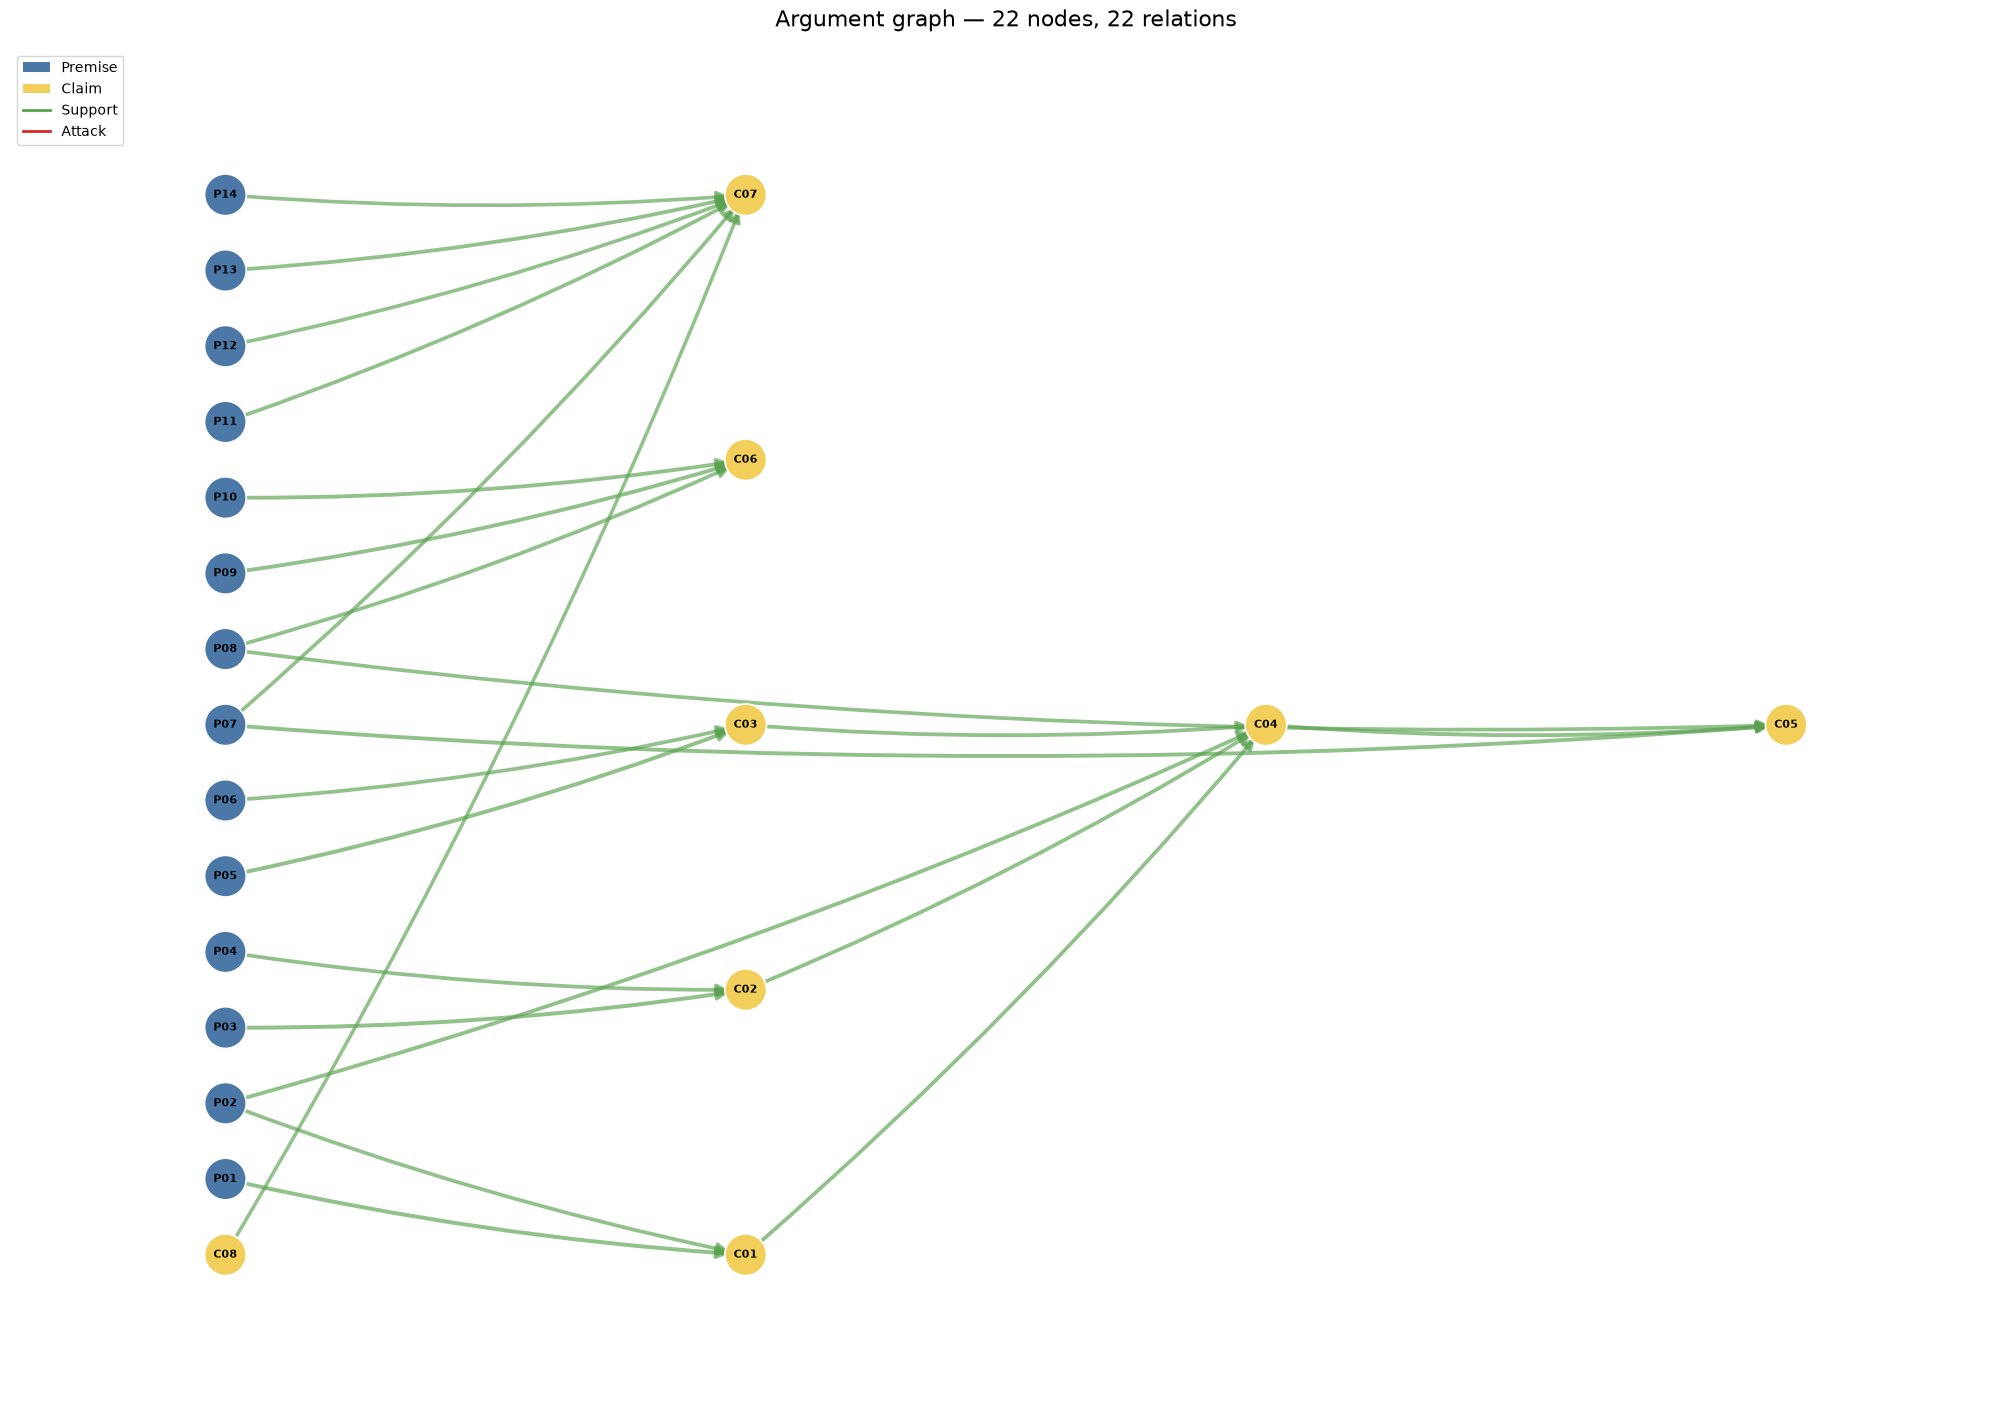

In [22]:
displayed_graph = visualize_graph(bi_legal_G)

In [23]:
# bi_legal_G.add_edges_from([(rel[0] + rel[1], rel[0] + rel[2]) for rel in relations_df[arguments_df["doc_id"] == "116062204"][["doc_id", "source", "target"]].values.tolist()])
# bi_legal_G.add_nodes_from([arg[0] + "." + arg[1] for arg in arguments_df[arguments_df["doc_id"] == "116062204"][["doc_id", "arg_id"]].values.tolist()])


# Merging two graphs

In [24]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sentence_transformers import models, SentenceTransformer

/tmp/ipykernel_21158/3198239693.py:4: DeprecationWarning: Importing from 'sentence_transformers.models' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.modules' instead.
  from sentence_transformers import models, SentenceTransformer


In [25]:
ENCODER_PATH = "bge_model/bge-small-uk-law-v1_1/final/encoder"
TOKENIZER_PATH = "bge_model/bge-small-uk-law-v1_1/final/tokenizer"

In [26]:
search_roots = (Path.cwd(), *Path.cwd().parents)
model_base = next(
    (
        base
        for root in search_roots
        for base in (root, root / "src" / "legal_data_doc_parts")
        if (base / ENCODER_PATH).is_dir() and (base / TOKENIZER_PATH).is_dir()
    ),
    None,
)
if model_base is None:
    raise FileNotFoundError(
        f"Could not locate {ENCODER_PATH!r} and {TOKENIZER_PATH!r} from {Path.cwd()}"
    )

In [27]:
transformer = models.Transformer(
    str(model_base / ENCODER_PATH),
    tokenizer_name_or_path=str(model_base / TOKENIZER_PATH),
)

pooling = models.Pooling(
    transformer.get_embedding_dimension(),
    pooling_mode = "mean",
)

argument_encoder = SentenceTransformer(modules=[transformer, pooling])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: /home/vegura/Projects/study/legal-data-doc-parts/src/legal_data_doc_parts/bge_model/bge-small-uk-law-v1_1/final/encoder
Key                 | Status  | 
--------------------+---------+-
pooler.dense.weight | MISSING | 
pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
The `tokenizer_name_or_path` argument is deprecated and will be removed in a future version. Please use the same path for the model and processor.


In [28]:
def construct_case_graph(doc_id: str):
    arg_sampled_df = arguments_df[arguments_df["doc_id"] == doc_id]
    rel_sampled_df = relations_df[relations_df["doc_id"] == doc_id]

    case_G = nx.DiGraph()
    for row in arg_sampled_df.itertuples(index=False):

        case_G.add_node(
            doc_id + "." + row.arg_id,
            arg_type=row.arg_type,
            argumentative_role=row.arg_argtype,
            text=row.arg_text,
            embedding=argument_encoder.encode(row.arg_text, batch_size=1, show_progress_bar=False).tolist(),
        )

    for row in rel_sampled_df.itertuples(index=False):
        case_G.add_edge(
            doc_id + "." + row.source,
            doc_id + "." + row.target,
            relation=row.relation,
            confidence=float(row.confidence),
            relation_embedding=argument_encoder.encode(row.justification, batch_size=1, show_progress_bar=False).tolist(),
        )

    return case_G

In [29]:
case_1_G = construct_case_graph("116075685")
case_2_G = construct_case_graph("116125191")

In [30]:
arguments_df[arguments_df["doc_id"] == "116125191"].shape, arguments_df[arguments_df["doc_id"] == "116075685"].shape

((38, 5), (132, 5))

#### Distance for embeddings function

In [31]:
def process_distances(embeddings_1, embeddings_2, global_batch_size, device="cuda"):
    embeddings_1 = np.asanyarray(embeddings_1, dtype=np.float32)
    embeddings_2 = np.asanyarray(embeddings_2, dtype=np.float32)

    n1 = embeddings_1.shape[0]
    n2 = embeddings_2.shape[0]

    distances = np.empty((n1, n2), dtype=np.float32)
    with torch.inference_mode():
        for global_start_1 in range(0, n1, global_batch_size):
            global_end_1 = min(global_start_1 + global_batch_size, n1)
            global_embeddings_1 = torch.as_tensor(
                embeddings_1[global_start_1: global_end_1],
                dtype=torch.float32,
                device=device,
            )
            global_embeddings_1 = F.normalize(global_embeddings_1, p=2, dim=1)
            x = global_embeddings_1

            for global_start_2 in range(0, n2, global_batch_size):
                global_end_2 =  min(global_start_2 + global_batch_size, n2)
                global_embeddings_2 = torch.as_tensor(
                    embeddings_2[global_start_2: global_end_2],
                    dtype=torch.float32,
                    device=device,
                )
                global_embeddings_2 = F.normalize(global_embeddings_2, p=2, dim=1)
                y = global_embeddings_2

                similarity = (x @ y.T).cpu().numpy()
                distances[global_start_1: global_end_1, global_start_2: global_end_2] = similarity

                del y, similarity, global_embeddings_2
            del global_embeddings_1

        return distances

Check if the function works correctly

In [32]:
A = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [1.0, 1.0],
])

B = np.array([
    [1.0, 0.0],
    [0.0, 1.0],
    [-1.0, 0.0],
    [1.0, 1.0],
])

A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

S = A_norm @ B_norm.T

S

array([[ 1.        ,  0.        , -1.        ,  0.70710678],
       [ 0.        ,  1.        ,  0.        ,  0.70710678],
       [ 0.70710678,  0.70710678, -0.70710678,  1.        ]])

In [33]:
process_distances(A, B, 1)

array([[ 1.        ,  0.        , -1.        ,  0.70710677],
       [ 0.        ,  1.        ,  0.        ,  0.70710677],
       [ 0.70710677,  0.70710677, -0.70710677,  0.99999994]],
      dtype=float32)

## Cross-graph similarity

In [34]:
case_1_G.nodes

NodeView(('116075685.P01', '116075685.P02', '116075685.P03', '116075685.C01', '116075685.P04', '116075685.P05', '116075685.P06', '116075685.C02', '116075685.P07', '116075685.P08', '116075685.P09', '116075685.C03', '116075685.P10', '116075685.P11', '116075685.P12', '116075685.C04', '116075685.P13', '116075685.P14', '116075685.P15', '116075685.C05', '116075685.P16', '116075685.P17', '116075685.P18', '116075685.C06', '116075685.P19', '116075685.P20', '116075685.P21', '116075685.C07', '116075685.P22', '116075685.P23', '116075685.P24', '116075685.C08', '116075685.P25', '116075685.P26', '116075685.P27', '116075685.C09', '116075685.P28', '116075685.P29', '116075685.P30', '116075685.C10', '116075685.C11', '116075685.C12', '116075685.C13', '116075685.C14', '116075685.C15', '116075685.P31', '116075685.P32', '116075685.P33', '116075685.C16', '116075685.C17', '116075685.C18', '116075685.C19', '116075685.C20', '116075685.C21', '116075685.C22', '116075685.C23', '116075685.C24', '116075685.C25', '116

In [35]:
def transition_matrix(A):
    degree = A.sum(axis=1)
    degree[degree == 0] = 1
    return A / degree[:, None]

In [36]:
mask = np.zeros(shape=(case_1_G.number_of_nodes(), case_2_G.number_of_nodes()))
for i, u in enumerate(case_1_G.nodes):
    for j, v in enumerate(case_2_G.nodes):
        if case_1_G.nodes[u]["arg_type"] == case_2_G.nodes[v]["arg_type"]:
            mask[i, j] = 1

In [37]:
def cross_graph_similarity(G1: nx.Graph, G2: nx.Graph, alpha, tol=1e-6, mask=None):
    emb1 = np.stack([
        G1.nodes[node]["embedding"]
        for node in G1.nodes
    ])
    emb2 = np.stack([
        G2.nodes[node]["embedding"]
        for node in G2.nodes
    ])
    # S - current belief that node i corresponds to j
    S_0 = process_distances(emb1, emb2, 1)

    if mask is not None:
        S_0 *= mask

    adj_1 = nx.to_numpy_array(G1)
    adj_2 = nx.to_numpy_array(G2)

    p_1 = transition_matrix(adj_1)
    p_2 = transition_matrix(adj_2)

    S = S_0.copy()
    for iteration in range(100):
        S_struct = p_1.T @ S @ p_2

        max_val = S_struct.max()
        if max_val > 0:
            S_struct = S_struct / max_val

        S_new = alpha * S_struct + (1 - alpha) * S_0

        print(f"Iteration -> {iteration}, with changes -> {np.linalg.norm(S_new - S)}")

        if mask is not None:
            S_new *= mask

        if np.linalg.norm(S_new - S) < tol:
            S = S_new
            break

        S = S_new
    return S

In [45]:
graph_sim = cross_graph_similarity(case_1_G, case_2_G, alpha=0.05, mask=mask)

Iteration -> 0, with changes -> 1.9766532628741844
Iteration -> 1, with changes -> 3.3398519877852194e-05
Iteration -> 2, with changes -> 3.092387279718116e-13


In [46]:
graph_sim

array([[0.70572072, 0.81373143, 0.79871941, ..., 0.60260528, 0.7586593 ,
        0.73761749],
       [0.69804275, 0.84319115, 0.81918311, ..., 0.57365614, 0.78480631,
        0.68582433],
       [0.73938197, 0.81112087, 0.79786527, ..., 0.59861839, 0.7789554 ,
        0.7052747 ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], shape=(132, 38))

In [47]:
np.save("result.npy", graph_sim)

In [48]:
def top_matches(
    G1: nx.Graph,
    G2: nx.Graph,
    S: np.ndarray,
    top_k: int = 10,
    same_type_only: bool = True,
):
    """Return up to top_k candidates per source node, ranked by similarity."""
    nodes1 = list(G1.nodes)
    nodes2 = list(G2.nodes)

    if S.shape != (len(nodes1), len(nodes2)):
        raise ValueError("S must have one row per G1 node and one column per G2 node")
    if not isinstance(top_k, (int, np.integer)) or top_k < 0:
        raise ValueError("top_k must be a non-negative integer")

    results = []
    for i, node1 in enumerate(nodes1):
        type1 = G1.nodes[node1].get("arg_type")
        candidates = []

        for j, node2 in enumerate(nodes2):
            type2 = G2.nodes[node2].get("arg_type")
            if same_type_only and (type1 is None or type2 is None or type1 != type2):
                continue

            candidates.append({
                "graph1_node": node1,
                "graph1_text": G1.nodes[node1].get("text"),
                "graph1_type": type1,
                "graph2_node": node2,
                "graph2_text": G2.nodes[node2].get("text"),
                "graph2_type": type2,
                "similarity": float(S[i, j]),
            })

        candidates.sort(key=lambda candidate: candidate["similarity"], reverse=True)
        for rank, candidate in enumerate(candidates[:top_k], start=1):
            results.append({**candidate, "rank": rank})

    return results

In [49]:
matches = top_matches(case_1_G, case_2_G, graph_sim, top_k=5)

In [50]:
matches.sort(key=lambda entry: entry.get("similarity", 0), reverse=True)

In [51]:
matches

[{'graph1_node': '116075685.C36',
  'graph1_text': 'відповідно до ст. 124 КПК України, підлягають стягненню з ОСОБА_5 на користь держави.',
  'graph1_type': 'CLAIM',
  'graph2_node': '116125191.C09',
  'graph2_text': 'Суд вважає, що процесуальні витрати на залучення експерта, згідно зі статтею 124 КПК України, слід стягнути з обвинуваченої на користь держави.',
  'graph2_type': 'CLAIM',
  'similarity': 0.8964845041874763,
  'rank': 1},
 {'graph1_node': '116075685.C24',
  'graph1_text': '...обставиною, що пом`якшує покарання обвинуваченого, згідно зі ст. 66 КК України, є щире каяття.',
  'graph1_type': 'CLAIM',
  'graph2_node': '116125191.C05',
  'graph2_text': 'Обставинами, що у відповідності із статтею 66 КК України пом`якшують покарання, суд визнає щире каяття та добровільне відшкодування завданого збитку.',
  'graph2_type': 'CLAIM',
  'similarity': 0.8787244225589599,
  'rank': 1},
 {'graph1_node': '116075685.C10',
  'graph1_text': '1.20. Отже, ОСОБА_5 учинив злочин, передбачений ч.